# Frames from the modes — the motion toolkit, worked on a real vibration

This notebook runs the pieces of molbuilder's motion toolkit that `engines/vibration-frames.md` § 6.1 lists on one real vibration — a PySCF methanol, twelve modes, among them a stiff C–O stretch and the soft methyl torsion — and checks each against the science it stands on: `engines/vibration-frames.md` (the toolkit) and `science/vibrational-averaging.md` (the theory), molbuilder's documents (the Documents tab). Every number it checks is computed here from CODATA's constants and the science's closed forms, never typed; every check is an `assert`, so the notebook is a test as well as a demonstration — *Run All*, and a cell that stops names what broke.

**What it reads.** A vibration run's folder molbuilder carries in its package, made down its own road (`molbuilder describe` → `jobset prep` → `jobset launch`, by `tools/make_example_runs.py`): the description `task.json`, the run's record, and its result `methanol.spectra.json`. It is copied into a temporary projects tree, a new one at each *Run All*, and every frame set below is written there — nothing into your own tree.

**To run it on a vibration of your own**, save this notebook under another name first — an example changed in `notebooks/examples/` is replaced at the next `molbuilder examples` or installation (`execution/project-layout.md` § 2.6) — then point `carried` in the next cell at your calculation's folder — the one holding its `task.json` — and `run_folder` at its vibration run; it is copied into the temporary tree as the example's run is. The checks against the science hold for any harmonic vibration; what is this methanol's alone says so where it stands — its mode count (a non-linear molecule, nothing held; section 1), the torsion warm against the stiff modes (section 2), and its C–O bond, which the stiff mode is found by (section 3) and the torsion's turn and the map's mirror plane are measured against (sections 2 and 7) — change or drop it for your run.

**The model response.** No calculation runs here. Where a transport calculation would compute a property at each frame, this notebook takes a model, $X(Q) = e^{\sum_k a_k Q_k}$ — curved and lopsided like the contact bond of science § 4.3 — whose average over every state has a closed form, so each average and each error below is checked against the exact answer.

In [1]:
%matplotlib inline
import hashlib
import math
import os
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import constants, special

import molbuilder

# THE CALCULATION THIS NOTEBOOK READS -- a vibration run's folder molbuilder
# carries in its package, a staggered PySCF methanol, its record's temperature
# 300 K.  Yours: its calculation's folder, the one holding its task.json.
carried = molbuilder.data_dir() / "examples" / "vibration-frames-run" / "methanol"

# A TEMPORARY PROJECTS TREE, a new one at each Run All: the calculation copied
# in, every frame set below written there.
scratch = tempfile.TemporaryDirectory(prefix="vibration-frames-")
tree = Path(scratch.name) / "projects"
shutil.copytree(carried, tree / "P" / "spectrum" / carried.name)
os.environ["MOLBUILDER_PROJECTS"] = str(tree)

from molbuilder.postprocess import (dist, infrared_view, openable, oscillator,
                                    projects_root, read_frame_set, sampling,
                                    states, structure_dir, topic_dir, vibration,
                                    weights_for_set, write_frame_set)

# ITS VIBRATION RUN, in the copy -- a PySCF vibration's one run.
run_folder = structure_dir("P", "spectrum", carried.name) / "01_freq" / "run-0"
assert projects_root() == tree
T = 300.0                                # the temperature every state below starts at, K
warm = states.thermal(temperature_k=T)   # a thermal start at T -- a chain of one step
SEED = 20261127                          # every draw's seed
print("the run's folder, in the temporary tree:", run_folder.relative_to(tree))

the run's folder, in the temporary tree: P/spectrum/methanol/01_freq/run-0


## 1. The vibration, and where it came from

`vibration(run_folder)` reads the run through the run door: its modes and what every mode shares, and its provenance — the run, the sha256 of its result JSON (which every frame set written from it records), and frame 0's record of the relaxation its geometry came from. The result is the file the run door opens in the run's folder (`openable`, as the Results tab opens it). A PySCF run's deck records no settings, so there is no relaxation record: `v.relaxation_said` says why, and every set written from this run says it is no transport citation (`engines/vibration-frames.md` § 1).

In [2]:
v = vibration(run_folder)
result = Path(openable(run_folder)[0])
assert v.run == run_folder
assert v.result_sha256 == hashlib.sha256(result.read_bytes()).hexdigest()
assert not any(m.has_imag for m in v.modes)
# THIS METHANOL'S: a non-linear molecule with nothing held has 3N - 6 modes.
assert len(v.modes) == 3 * len(v.masses_amu) - 6
print("read:", v.run.relative_to(tree), "--", result.name)
print("its result's sha256:", v.result_sha256)
print("frame 0's relaxation record:", v.relaxation_calculation)
print("  why:", v.relaxation_said)
print("the record's temperature:", v.record_temperature_k, "K")
print("atoms:", " ".join(v.element_symbols))
print(len(v.modes), "modes (cm-1):", ", ".join(f"{m.index_1based}: {m.frequency_cm1:.1f}" for m in v.modes))

read: P/spectrum/methanol/01_freq/run-0 -- methanol.spectra.json
its result's sha256: 2edb018988a1196a9cba440b31e66501336d176ea51c44881ceeb85140cfc51d
frame 0's relaxation record: None
  why: methanol's deck records no settings (a PySCF deck states none), so the set states no info.calculation and is no transport citation
the record's temperature: 300.0 K
atoms: C O H H H H
12 modes (cm-1): 1: 338.1, 2: 1070.6, 3: 1107.9, 4: 1171.8, 5: 1365.2, 6: 1469.1, 7: 1475.0, 8: 1494.3, 9: 2961.8, 10: 3012.4, 11: 3105.5, 12: 3824.0


## 2. Each mode at 300 K — numbers computed, never typed

A mode's zero-point amplitude is $Q_{\mathrm{zp}} = \sqrt{\hbar/2\omega}$ (science § 2b.1), and in equilibrium at $T$ its coordinate is a bell curve of spread $\sigma^2 = Q_{\mathrm{zp}}^2(2\bar n + 1)$, $\bar n = 1/(e^{hc\tilde\nu/k_BT} - 1)$ its mean number of quanta (science § 2d.3's boxed formula). Here both are computed from CODATA's constants (`scipy.constants`) and held against what the toolkit binds to each mode, `m.bind(states.thermal(temperature_k=300))`, within $10^{-8}$: molbuilder states its zero-point constant to eight figures (science § 2b.1), which puts its numbers within about $10^{-9}$ of CODATA's.

The softest mode, the methyl torsion, is warm — the cell prints how many quanta it holds — while the stiff modes sit at their zero-point motion (this methanol's, against science § 2e.2's table). **The torsion appears only here**: its harmonic width is a model. A torsion is a hindered rotation, outside the harmonic picture (science § 7, item 1), and the cell below says by how much, from the run: how far its three frames' outer nodes turn the atom it moves most about the C–O bond, and what the mode's straight-line pattern makes of that turn.

**It is left out of every motion below**: the snapshot sets of sections 7 to 11 move the stiff modes alone — the modes a frame set is for, stiff against $k_BT$, a soft one left out of a motion by its window (science § 2e.2). A person picks the modes a motion moves with `v.mode_selection()` — every real mode, then `.window(low, high)`, `.only`, `.add` and `.drop` in steps, each acting on what the step before left (science § 2c.5) — and `v.motion(chain, modes=selection)` moves those alone, the steps written with every set: here every real mode but the torsion found above, `v.mode_selection().drop([k_t])`.

In [3]:
def q_zp_codata(nu_cm1):
    # Q_zp = sqrt(hbar / 2 omega), omega = 2 pi c nu (science § 2b.1), in amu^1/2 Å
    omega = 2 * math.pi * constants.c * nu_cm1 * 100.0
    return math.sqrt(constants.hbar / (2 * omega) / constants.atomic_mass) * 1e10


def nbar_codata(nu_cm1, t):
    # Bose and Einstein's mean number of quanta (science § 2d.3)
    return 1.0 / math.expm1(constants.h * constants.c * nu_cm1 * 100.0 / (constants.k * t))


order = [m.index_1based for m in v.modes]        # the result's order -- a motion's columns
sigma_th = {}                                    # each mode's thermal spread at T, from CODATA
held_at = {}                                     # each mode's mean quanta at T, the toolkit's
print(f"{'mode':>4} {'cm-1':>8} {'sigma/Q_zp':>11} {'mean quanta':>12}")
for m in v.modes:
    d = m.bind(warm)
    qzp, nbar = q_zp_codata(m.frequency_cm1), nbar_codata(m.frequency_cm1, T)
    sigma_th[m.index_1based] = qzp * math.sqrt(2 * nbar + 1)
    held_at[m.index_1based] = d.mean_quanta
    assert math.isclose(m.zero_point_amplitude_amu12_ang, qzp, rel_tol=1e-8)
    assert math.isclose(d.mean_quanta, nbar, rel_tol=1e-8)
    assert math.isclose(d.spread_amu12_ang, sigma_th[m.index_1based], rel_tol=1e-8)
    print(f"{m.index_1based:>4} {m.frequency_cm1:>8.1f} {d.spread_amu12_ang / qzp:>11.5f} {d.mean_quanta:>12.4g}")
freqs = np.array([m.frequency_cm1 for m in v.modes])
assert np.allclose(oscillator.bose_einstein_mean_quanta(freqs, T),
                   [held_at[k] for k in order], rtol=1e-12, atol=0)

torsion = min(v.modes, key=lambda m: m.frequency_cm1)      # the softest mode
k_t = torsion.index_1based
# THIS METHANOL'S CONTRAST, against science § 2e.2's table at 300 K: the torsion
# holds more quanta than a 500 cm-1 mode does (0.100); no mode from 1000 cm-1 up
# holds more than a 1000 cm-1 one does (0.00833).
assert held_at[k_t] > nbar_codata(500.0, T)
assert all(held_at[m.index_1based] <= nbar_codata(1000.0, T)
           for m in v.modes if m.frequency_cm1 >= 1000.0)
print(f"\nthe torsion: mode {k_t}, {torsion.frequency_cm1:.1f} cm-1, {held_at[k_t]:.3f} mean quanta at {T:g} K")

# ITS HARMONIC WIDTH IS A MODEL: the atom it moves most, at its three frames'
# outer nodes (± sqrt(3) sigma), turned about the C-O bond -- an angle -- and
# stretched from the atom it is bonded to by the mode's straight-line pattern.
el = v.element_symbols
C, O = el.index("C"), el.index("O")              # this methanol's C-O bond
r0 = v.positions_ang
bond = float(np.linalg.norm(r0[C] - r0[O]))
u_co = (r0[C] - r0[O]) / bond
L_t = torsion.eigenvector_canonical_over_atoms_per_amu12
A = int(np.argmax(np.linalg.norm(L_t, axis=1)))
f3 = torsion.bind(warm).frames(3)
move = float(np.linalg.norm(f3.positions_ang[1, A] - r0[A]))
arm = r0[A] - r0[O]
radius = float(np.linalg.norm(arm - (arm @ u_co) * u_co))   # its distance from the C-O axis
partner = int(np.argsort(np.linalg.norm(r0 - r0[A], axis=1))[1])   # the atom it is bonded to
rest = float(np.linalg.norm(r0[A] - r0[partner]))
stretched = float(np.linalg.norm(f3.positions_ang[1, A] - f3.positions_ang[1, partner]))
print(f"its three frames move the {el[A]} {move:.2f} Å -- a {math.degrees(move / radius):.0f}° turn about the "
      f"C-O bond, which the straight-line pattern makes an {el[partner]}-{el[A]} stretch from "
      f"{rest:.3f} to {stretched:.3f} Å: a hindered rotation, outside the harmonic picture")
# ONE PHOTON ON IT, against science § 7 item 1's 1 eV mark: under it too -- the
# mark is not a bound
e_t = torsion.bind(warm.add_quantum()).mean_quanta * torsion.oscillator.quantum_ev
print(f"one photon on it would put {e_t:.3f} eV into it, under science § 7 item 1's 1 eV mark too: "
      f"a mark, not a bound")

# THE MODES THE SNAPSHOTS MOVE (science § 2c.5): every real mode but the torsion
stiff = v.mode_selection().drop([k_t])
moving = stiff.final()                           # their numbers, in the result's order
assert k_t not in moving and len(moving) == len(v.modes) - 1
print("the snapshots below move", stiff)

mode     cm-1  sigma/Q_zp  mean quanta
   1    338.1     1.22171       0.2463
   2   1070.6     1.00591     0.005925
   3   1107.9     1.00494      0.00495
   4   1171.8     1.00363     0.003639
   5   1365.2     1.00143     0.001436
   6   1469.1     1.00087    0.0008721
   7   1475.0     1.00085    0.0008477
   8   1494.3     1.00077    0.0007726
   9   2961.8     1.00000    6.777e-07
  10   3012.4     1.00000    5.316e-07
  11   3105.5     1.00000    3.402e-07
  12   3824.0     1.00000    1.085e-08

the torsion: mode 1, 338.1 cm-1, 0.246 mean quanta at 300 K
its three frames move the H 0.40 Å -- a 25° turn about the C-O bond, which the straight-line pattern makes an O-H stretch from 0.965 to 1.058 Å: a hindered rotation, outside the harmonic picture
one photon on it would put 0.063 eV into it, under science § 7 item 1's 1 eV mark too: a mark, not a bound
the snapshots below move ModeSelection(modes 2, 3, 4, 5, 6, 7, 8, 9, 10, 11 and 12: every real mode; mode 1 dropped)


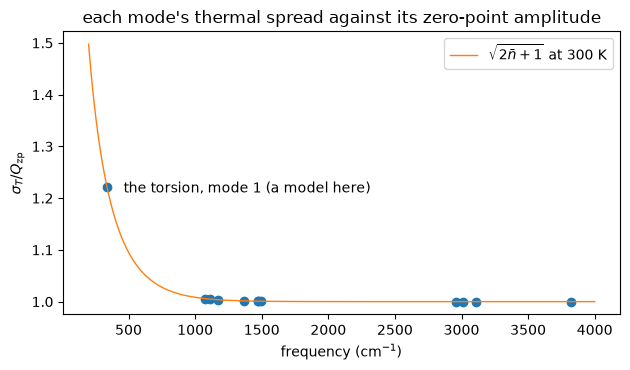

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ratio = [sigma_th[k] / q_zp_codata(v.mode(k).frequency_cm1) for k in order]
ax.plot(freqs, ratio, "o")
nu = np.linspace(200.0, 4000.0, 400)
ax.plot(nu, np.sqrt(2 * oscillator.bose_einstein_mean_quanta(nu, T) + 1), lw=1,
        label=r"$\sqrt{2\bar n + 1}$ at 300 K")
ax.annotate(f"the torsion, mode {k_t} (a model here)", (torsion.frequency_cm1, ratio[order.index(k_t)]),
            xytext=(12, -4), textcoords="offset points")
ax.set_xlabel(r"frequency (cm$^{-1}$)")
ax.set_ylabel(r"$\sigma_T / Q_{\mathrm{zp}}$")
ax.set_title("each mode's thermal spread against its zero-point amplitude")
ax.legend()
plt.tight_layout()
plt.show()

## 3. The stiff mode the photon goes on — the C–O stretch, found from the run

A frame set is for a stiff mode, one that sits at its zero-point motion at the temperature asked (science § 2e.2), and one photon goes on such a mode in every section below. It is found from the run, never typed: the mode whose motion changes the C–O bond length most per unit $Q$, $\lvert(\mathbf L_{\mathrm C} - \mathbf L_{\mathrm O})\cdot\hat{\mathbf u}_{\mathrm{CO}}\rvert$ from its eigenvector over the atoms (science § 2b.2: an atom moves $Q\,\mathbf L_A$), $\hat{\mathbf u}_{\mathrm{CO}}$ the bond's direction — the C–O stretch, an infrared-active mode (its intensity from the result, `infrared_view`). The harmonic picture is read for it: one photon puts well under 1 eV into it — science § 7, item 1's mark, which the torsion of section 2 passes too: a mark, not a bound — and its photon set's largest move and the C–O change it makes are printed, to be read against the bond.

In [5]:
def bond_rate(m):
    # d|R_C - R_O|/dQ = (L_C - L_O) . u_CO, in Å per amu^1/2 Å
    L = m.eigenvector_canonical_over_atoms_per_amu12
    return float((L[C] - L[O]) @ u_co)


stretch = max(v.modes, key=lambda m: abs(bond_rate(m)))
k_s = stretch.index_1based
intensity = next(x.intensity_km_mol for x in infrared_view(result).modes if x.index_1based == k_s)
qz = stretch.zero_point_amplitude_amu12_ang      # the mode's own -- CODATA's within 1e-8 (section 2)
nbar_s = held_at[k_s]                            # its mean quanta at T, the toolkit's (section 2)
assert nbar_s <= nbar_codata(1000.0, T)          # stiff: science § 2e.2's 1000 cm-1 row or colder
for m in v.modes:
    print(f"mode {m.index_1based:>2}, {m.frequency_cm1:7.1f} cm-1: dR_CO/dQ {bond_rate(m):+.4f} Å per amu^1/2 Å")
print(f"\nthe stiff mode: mode {k_s}, {stretch.frequency_cm1:.1f} cm-1 -- the C-O stretch, "
      f"infrared {intensity:.1f} km/mol, {nbar_s:.4f} mean quanta at {T:g} K")

assert k_s in moving                             # one of the modes the snapshots move
# THE HARMONIC PICTURE, READ FOR IT: one photon's energy in the mode against
# science § 7 item 1's 1 eV mark -- a mark, not a bound (section 2's torsion
# passes it too) -- and its five frames' largest move and C-O change, printed
# beside the bond.
photon_s = stretch.bind(warm.add_quantum())
energy = photon_s.mean_quanta * stretch.oscillator.quantum_ev
assert energy < 1.0                              # under the mark
f5 = photon_s.frames(5)
change = np.linalg.norm(f5.positions_ang[:, C] - f5.positions_ang[:, O], axis=1) - bond
rms = photon_s.spread_amu12_ang * abs(bond_rate(stretch))
print(f"one photon on it: {photon_s.mean_quanta:.4f} quanta, {energy:.3f} eV in the mode; its five frames "
      f"move an atom {f5.max_atom_displacement_ang.max():.3f} Å at most and the C-O bond "
      f"({bond:.3f} Å) by {np.abs(change).max():.3f} Å at their farthest, "
      f"{100 * np.abs(change).max() / bond:.0f} % of it, {rms:.3f} Å r.m.s.")

mode  1,   338.1 cm-1: dR_CO/dQ -0.0000 Å per amu^1/2 Å
mode  2,  1070.6 cm-1: dR_CO/dQ -0.1481 Å per amu^1/2 Å
mode  3,  1107.9 cm-1: dR_CO/dQ -0.3352 Å per amu^1/2 Å
mode  4,  1171.8 cm-1: dR_CO/dQ -0.0000 Å per amu^1/2 Å
mode  5,  1365.2 cm-1: dR_CO/dQ -0.0042 Å per amu^1/2 Å
mode  6,  1469.1 cm-1: dR_CO/dQ -0.0000 Å per amu^1/2 Å
mode  7,  1475.0 cm-1: dR_CO/dQ +0.0691 Å per amu^1/2 Å
mode  8,  1494.3 cm-1: dR_CO/dQ +0.0661 Å per amu^1/2 Å
mode  9,  2961.8 cm-1: dR_CO/dQ -0.0408 Å per amu^1/2 Å
mode 10,  3012.4 cm-1: dR_CO/dQ +0.0000 Å per amu^1/2 Å
mode 11,  3105.5 cm-1: dR_CO/dQ -0.0125 Å per amu^1/2 Å
mode 12,  3824.0 cm-1: dR_CO/dQ +0.0222 Å per amu^1/2 Å

the stiff mode: mode 3, 1107.9 cm-1 -- the C-O stretch, infrared 39.0 km/mol, 0.0049 mean quanta at 300 K
one photon on it: 1.0099 quanta, 0.139 eV in the mode; its five frames move an atom 0.109 Å at most and the C-O bond (1.407 Å) by 0.136 Å at their farthest, 10 % of it, 0.072 Å r.m.s.


## 4. The model response and its closed forms

$X(Q) = e^{\sum_k a_k Q_k}$ over the modes the snapshots move (section 2's selection), with $a_k = c_k/\sigma_k$: $c = 0.6$ on the C–O stretch and $\pm 0.15$ on every other. **The 0.6 is a model's**: science § 4.3's example of a strongly lopsided response, $a\sigma = 0.6$ for a contact bond, put on the stretch the photon excites so the response is curved and lopsided along that mode — not methanol's tunnelling. Read as a tunnelling decay $e^{-2\kappa d}$ with $d$ the C–O length (science § 4.3, $a = 2\kappa d'$), it would be $2\kappa = a/\lvert dR_{\mathrm{CO}}/dQ\rvert$, which the cell prints: a model's number, not a molecule's. Its average over each state is a closed form (science § 2b.5): a thermal mode's $e^{a^2\sigma^2/2}$; for any list of chances $p_n$ over the levels, science § 2b.5's $n$-quanta row summed over science § 2e.1's list, $\sum_n p_n\,e^{\lambda^2/2}L_n(-\lambda^2)$, $\lambda = aQ_{\mathrm{zp}}$, $L_n$ the Laguerre polynomial; the molecule's, the modes moving independently, the product of each mode's own (science § 2c.1). The lists are built here with numpy from science § 2e.2's rules — a thermal start $p_n = \bar n^n/(\bar n + 1)^{n+1}$; a quantum added, $p'_n \propto n\,p_{n-1}$; a quantum removed, $p'_n \propto (n+1)\,p_{n+1}$ — not taken from the toolkit.

Because $X(Q)\,X(-Q) = 1$, a mirrored pair's mean $\tfrac12(X(Q) + X(-Q))$ has variance $\tfrac12(\langle X^2\rangle + 1) - \langle X\rangle^2$, with $\langle X^2\rangle$ the same closed form at $2a$: the error of a paired set's average is known before a single frame is drawn.

In [6]:
c = {k: (0.6 if k == k_s else 0.15 * (-1) ** i) for i, k in enumerate(moving)}
a = {k: c[k] / sigma_th[k] for k in moving}
# THE MODEL'S 0.6, READ AS A TUNNELLING DECAY with the C-O length (science § 4.3,
# a = 2 kappa d'): 2 kappa = a / |dR_CO/dQ|
print(f"the 0.6 on the stretch, read as a decay with the C-O length: 2 kappa = "
      f"{abs(a[k_s] / bond_rate(stretch)):.1f} per Å -- a model's number, not methanol's")


def linear(q, columns):
    # a . Q at each frame, column by column: the same operations on a snapshot
    # and on its mirror, so the mirror's is exactly minus its own (a matrix
    # product's rounding need not be the same for the two rows)
    out = np.zeros(len(q))
    for i, k in enumerate(columns):
        out = out + q[:, i] * a[int(k)]
    return out


def X(s):
    # the model response at each frame of a set -- frame 0 first, one value per frame
    return np.exp(linear(s.q_amu12_ang, s.mode_index_1based))


def thermal_list(nbar, levels=600):
    n = np.arange(levels)
    return nbar ** n / (nbar + 1.0) ** (n + 1)


def added(p):      # a quantum added (science § 2e.2): p'_n = n p_(n-1) / (<n> + 1)
    q = np.arange(len(p) + 1) * np.concatenate([[0.0], p])
    return q / q.sum()


def removed(p):    # a quantum removed (science § 2e.2): p'_n = (n + 1) p_(n+1) / <n>
    q = np.arange(1, len(p)) * p[1:]
    return q / q.sum()


def thermal_mgf(k, s=1.0):
    # <exp(s a_k Q_k)> in the thermal state: exp(s^2 a^2 sigma^2 / 2) (science § 2b.5)
    return math.exp((s * a[k] * sigma_th[k]) ** 2 / 2)


def list_mgf(p, k, s=1.0):
    # <exp(s a_k Q_k)> for a list p_n: science § 2b.5's n-quanta row summed over
    # science § 2e.1's list, sum_n p_n e^(lambda^2/2) L_n(-lambda^2), lambda = s a Q_zp
    lam = s * a[k] * q_zp_codata(v.mode(k).frequency_cm1)
    n = np.arange(len(p))
    return float(np.sum(p * math.exp(lam ** 2 / 2) * special.eval_laguerre(n, -lam ** 2)))


def molecule(apart=None, s=1.0):
    # <X^s> over the motion: every mode it moves thermal, the stretch in the list `apart` when given
    out = 1.0
    for k in moving:
        out *= list_mgf(apart, k, s) if (k == k_s and apart is not None) else thermal_mgf(k, s)
    return out


def pair_var(mean, mean_sq):
    # the variance of a mirrored pair's mean, X(Q) X(-Q) = 1
    return (mean_sq + 1) / 2 - mean ** 2


photon_list = added(thermal_list(nbar_codata(stretch.frequency_cm1, T)))   # one photon on the stretch
# MEHLER: the thermal list's form is the bell curve's, term by term (science § 2d.3),
# within science § 2e.6's one epsilon
assert math.isclose(list_mgf(thermal_list(nbar_codata(stretch.frequency_cm1, T)), k_s),
                    thermal_mgf(k_s), rel_tol=1e-12)
mean_th, mean2_th = molecule(), molecule(s=2.0)
mean_ph, mean2_ph = molecule(photon_list), molecule(photon_list, s=2.0)
print(f"<X>, every mode it moves thermal:          {mean_th:.6f}")
print(f"<X>, one photon on the C-O stretch:        {mean_ph:.6f}")
print(f"a pair mean's variance (thermal, photon):  {pair_var(mean_th, mean2_th):.5f}, {pair_var(mean_ph, mean2_ph):.5f}")

the 0.6 on the stretch, read as a decay with the C-O length: 2 kappa = 14.4 per Å -- a model's number, not methanol's
<X>, every mode it moves thermal:          1.339773
<X>, one photon on the C-O stretch:        1.819727
a pair mean's variance (thermal, photon):  0.31601, 1.10805


## 5. Each mode's draws against its state's density

A mode bound to a state draws its coordinate from its own random stream, `sampling.normal_stream((seed, mode, 0))`, one standard normal number $z$ per draw: the draw is the point where the state's distribution function reaches $\Phi(z)$ (science § 2d.5) — exactly, for the bell curve and for two quanta exactly alike, held within $10^{-9}$. Here the C–O stretch, thermal and with two quanta: the draws' mean square within five of its standard errors of science § 2b.3's — $\langle Q^2\rangle = \sigma^2$ thermal and $(2n+1)Q_{\mathrm{zp}}^2$ for $n$ quanta, its error from $\langle Q^4\rangle$, $3\sigma^4$ and $3(2n^2 + 2n + 1)Q_{\mathrm{zp}}^4$ — and each distribution's own fourth moment science § 2b.3's, within science § 2e.6's one epsilon.

thermal at 300 K: <Q^2> 0.015302 against 0.015367; <Q^4> 7.0840e-04
two quanta exactly: <Q^2> 0.075650 against 0.076080; <Q^4> 9.0295e-03


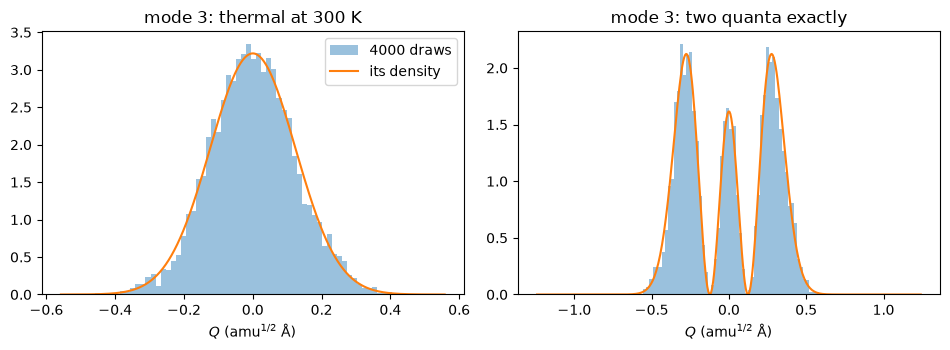

In [7]:
N1 = 4000
sigma_s = stretch.bind(warm).spread_amu12_ang    # the mode's own thermal spread
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, (chain, name, m2, m4) in zip(axes, (
        (warm, "thermal at 300 K", sigma_s ** 2, 3 * sigma_s ** 4),
        (states.level(2), "two quanta exactly", 5 * qz ** 2, 3 * 13 * qz ** 4))):
    d = stretch.bind(chain)
    q = d.draw(N1, seed=SEED)
    z = sampling.normal_stream((SEED, k_s, 0), N1)
    assert np.allclose(d.distribution.cdf(q), special.ndtr(z), rtol=0, atol=1e-9)
    assert abs(np.mean(q ** 2) - m2) < 5 * math.sqrt((m4 - m2 ** 2) / N1)
    assert math.isclose(d.distribution.moment(4), m4, rel_tol=1e-12)
    xs = np.linspace(-4.5 * math.sqrt(m2), 4.5 * math.sqrt(m2), 400)
    ax.hist(q, bins=60, density=True, alpha=0.45, label=f"{N1} draws")
    ax.plot(xs, d.distribution.pdf(xs), label="its density")
    ax.set_title(f"mode {k_s}: {name}")
    ax.set_xlabel(r"$Q$ (amu$^{1/2}$ Å)")
    print(f"{name}: <Q^2> {np.mean(q ** 2):.6f} against {m2:.6f}; <Q^4> {d.distribution.moment(4):.4e}")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Two kinds of quanta side by side — and one photon on the C–O stretch

A mode put directly in its first level, `states.level(1)`, and the thermal state of one mean quantum, `states.thermal(mean_quanta=1)`, hold the same spread, $\langle Q^2\rangle = 3Q_{\mathrm{zp}}^2$ (science § 2b.3), but not the same shape: two distributions, two Gauss rules — level 1's three frames at $0, \pm\sqrt5\,Q_{\mathrm{zp}}$ weighted 0.4, 0.3, 0.3 (science § 2b.4), the bell curve's at $0, \pm 3\,Q_{\mathrm{zp}}$ weighted $\tfrac23, \tfrac16, \tfrac16$. Of a sample at 300 K, the molecules that absorbed one photon on the C–O stretch, `states.thermal(temperature_k=300).add_quantum()`, hold $2\bar n + 1$ quanta on average and are in level 1 with chance $1/(\bar n + 1)^2$ (science § 2d.4) — on a stiff mode, nearly level 1 itself; its distribution the closed form `dist.QuantumAdded`. A detected anti-Stokes event, `.remove_quantum()`, and two events in a row, each against its list built here (science § 2e.2): at one mean quantum, means exactly 3, 2 and $\tfrac{10}{3}$. Two numbers that are one to rounding are held within science § 2e.6's one epsilon.

In [8]:
def one_epsilon(got, want):
    # science § 2e.6's one epsilon: within 1e-12 of the size of what is compared
    want = np.asarray(want, dtype=float)
    return float(np.abs(np.asarray(got) - want).max()) <= 1e-12 * float(np.abs(want).max())


one = stretch.bind(states.level(1))
mean1 = stretch.bind(states.thermal(mean_quanta=1))
photon = stretch.bind(warm.add_quantum())
x1, w1 = one.distribution.gauss_rule(3)
xm, wm = mean1.distribution.gauss_rule(3)
assert one_epsilon(x1 / qz, [-math.sqrt(5), 0.0, math.sqrt(5)])
assert one_epsilon(w1, [0.3, 0.4, 0.3])
assert one_epsilon(xm / qz, [-3.0, 0.0, 3.0])
assert one_epsilon(wm, [1 / 6, 2 / 3, 1 / 6])
for d in (one, mean1):
    assert math.isclose(d.distribution.moment(2), 3 * qz ** 2, rel_tol=1e-12)
assert isinstance(photon.distribution.base, dist.QuantumAdded)
assert math.isclose(photon.mean_quanta, 2 * nbar_s + 1, rel_tol=1e-12)
assert math.isclose(photon.state.populations[1], 1 / (nbar_s + 1) ** 2, rel_tol=1e-12)
print(photon.words)
print(f"  mean quanta {photon.mean_quanta:.4f} = 2 n + 1; in level 1: {photon.state.populations[1]:.4f} = 1/(n + 1)^2")

at_one = states.thermal(mean_quanta=1.0)
events = {
    "one quantum added": (at_one.add_quantum(), added(thermal_list(1.0)), 3.0),
    "one removed (anti-Stokes)": (at_one.remove_quantum(), removed(thermal_list(1.0)), 2.0),
    "added, then removed": (at_one.add_quantum().remove_quantum(),
                            removed(added(thermal_list(1.0))), 10 / 3),
}
for name, (chain, mine, mean) in events.items():
    st = stretch.bind(chain).state
    n = min(len(st.populations), len(mine))
    # within the one epsilon of the list's size: its chances sum to 1
    assert np.allclose(st.populations[:n], mine[:n], rtol=0, atol=1e-12), name
    assert math.isclose(st.mean_quanta, mean, rel_tol=1e-12), name
    print(f"{name:>28}: {np.round(st.populations[:5], 4)}  mean {st.mean_quanta:.4f}")

thermal at 300 K (0.00495 mean quanta); one quantum added
  mean quanta 1.0099 = 2 n + 1; in level 1: 0.9902 = 1/(n + 1)^2
           one quantum added: [0.     0.25   0.25   0.1875 0.125 ]  mean 3.0000
   one removed (anti-Stokes): [0.25   0.25   0.1875 0.125  0.0781]  mean 2.0000
         added, then removed: [0.0833 0.1667 0.1875 0.1667 0.1302]  mean 3.3333


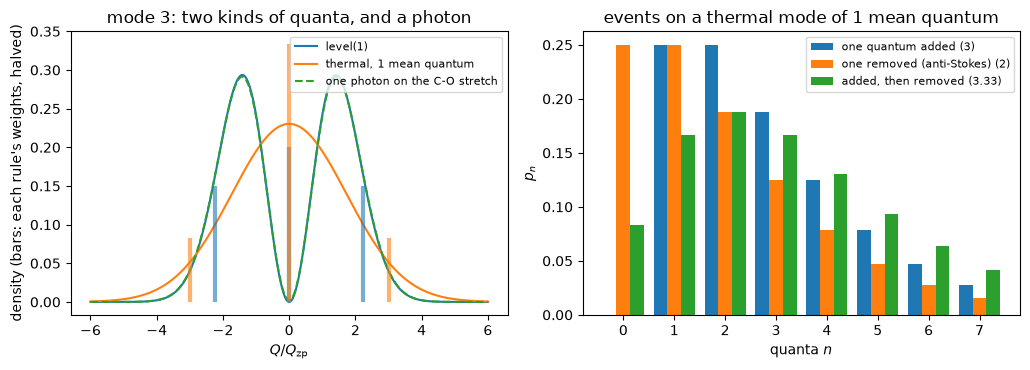

In [9]:
xs = np.linspace(-6 * qz, 6 * qz, 600)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.4, 3.8))
for d, label, style in ((one, "level(1)", "-"), (mean1, "thermal, 1 mean quantum", "-"),
                        (photon, "one photon on the C-O stretch", "--")):
    ax.plot(xs / qz, d.distribution.pdf(xs) * qz, style, label=label)
for x, w, colour in ((x1, w1, "C0"), (xm, wm, "C1")):
    ax.vlines(x / qz, 0, w * 0.5, colors=colour, lw=3, alpha=0.6)
ax.set_xlabel(r"$Q / Q_{\mathrm{zp}}$")
ax.set_ylabel("density (bars: each rule's weights, halved)")
ax.set_title(f"mode {k_s}: two kinds of quanta, and a photon")
ax.legend(fontsize=8)
for i, (name, (chain, mine, mean)) in enumerate(events.items()):
    bx.bar(np.arange(8) + (i - 1) * 0.27, mine[:8], width=0.27, label=f"{name} ({mean:.3g})")
bx.set_xlabel("quanta $n$")
bx.set_ylabel("$p_n$")
bx.set_title("events on a thermal mode of 1 mean quantum")
bx.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. One snapshot's displacement map, and every atom's covariance

`v.motion(states.thermal(temperature_k=300), modes=stiff)` binds the thermal state to every mode section 2's selection keeps; `.sample(N, seed=, antithetic=)` draws $N$ snapshots, each mode from its own stream, every atom moved by all those modes at once, $\mathbf R_A = \mathbf R_A^0 + \sum_k Q_k\mathbf L_{k,A}$ (`engines/vibration-frames.md` § 3.2). The map shows one snapshot's moves seen two ways, each with this methanol's mirror plane — the plane of its C, its O and the hydroxyl H — edge-on: across the C–O bond, and along it, the C in front of the O; every atom drawn as an open ring, atoms one behind the other labelled together, and the title saying how much of the largest move each view shows. Over the snapshots each atom's displacement has the covariance $\sum_k \sigma_k^2\,\mathbf L_{k,A}\mathbf L_{k,A}^{\mathsf T}$ (science § 2d.3), held here element by element within five of its standard errors, $\sqrt{(C_{ii}C_{jj} + C_{ij}^2)/N}$. Independent snapshots: mirrored pairs repeat each square, which halves $N$ for a second moment.

every atom's covariance, element by element: the worst 2.50 standard errors off


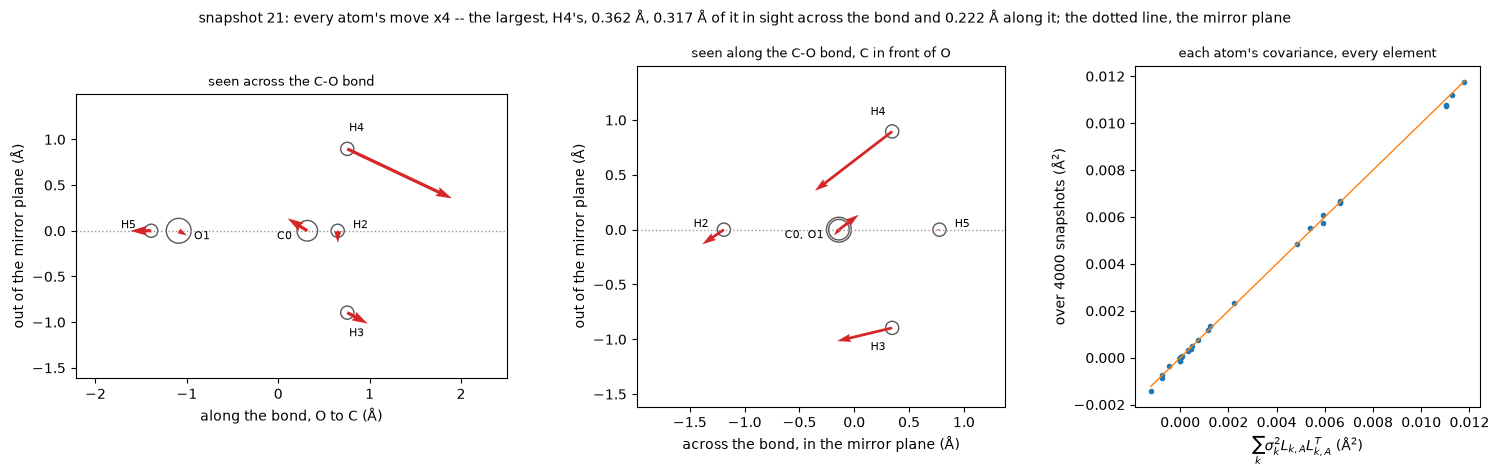

In [10]:
snaps = v.motion(warm, modes=stiff).sample(4000, seed=SEED, antithetic=False)
assert list(snaps.mode_index_1based) == moving
N3 = snaps.samples
worst, measured, expected = 0.0, [], []
for atom in range(len(v.masses_amu)):
    u = snaps.atom_moves_ang[1:, atom]
    got = u.T @ u / N3                                     # <u u^T>, <u> = 0
    want = sum(sigma_th[k] ** 2 * np.outer(v.mode(k).eigenvector_canonical_over_atoms_per_amu12[atom],
                                            v.mode(k).eigenvector_canonical_over_atoms_per_amu12[atom])
               for k in moving)
    se = np.sqrt((np.outer(np.diag(want), np.diag(want)) + want ** 2) / N3)
    worst = max(worst, float(np.max(np.abs(got - want) / se)))
    measured += list(got[np.triu_indices(3)])
    expected += list(want[np.triu_indices(3)])
assert worst < 5.0
print(f"every atom's covariance, element by element: the worst {worst:.2f} standard errors off")

f = 1 + int(np.argmax(snaps.max_atom_displacement_ang[1:41]))   # the largest move of the first forty
moves = snaps.atom_moves_ang[f]
mover = int(np.argmax(np.linalg.norm(moves, axis=1)))
# THIS METHANOL'S MIRROR PLANE: the plane of the C, the O and the hydroxyl H
# (the H nearest the O); both views hold it edge-on, the dotted line.
hydroxyl = min((i for i, e in enumerate(el) if e == "H"), key=lambda i: np.linalg.norm(r0[i] - r0[O]))
normal = np.cross(u_co, r0[hydroxyl] - r0[O])
normal = normal / np.linalg.norm(normal)
across = np.cross(normal, u_co)                  # in the mirror plane, across the bond
centre = r0.mean(axis=0)
views = (("seen across the C-O bond", u_co, normal, "along the bond, O to C (Å)"),
         ("seen along the C-O bond, C in front of O", across, normal, "across the bond, in the mirror plane (Å)"))
radius = {"C": 220, "O": 320}                    # marker sizes; every other element 90
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8), gridspec_kw={"width_ratios": [1.25, 1.25, 1.0]})
seen = []
for ax, (view, h, up, xlabel) in zip(axes, views):
    xy = np.column_stack([(r0 - centre) @ h, (r0 - centre) @ up])
    uv = np.column_stack([moves @ h, moves @ up])
    depth = (r0 - centre) @ np.cross(h, up)
    for atom in np.argsort(depth):               # the farthest drawn first, every marker open
        ax.scatter(*xy[atom], s=radius.get(el[atom], 90), facecolors="none", edgecolors="0.35", zorder=1)
    groups = []                                  # atoms one behind the other, labelled together
    for atom in range(len(el)):
        near = next((g for g in groups if np.linalg.norm(xy[g[0]] - xy[atom]) < 0.15), None)
        if near is None:
            groups.append([atom])
        else:
            near.append(atom)
    for g in groups:                             # each label on the side away from its nearest neighbour
        nearest = min((xy[b] for b in range(len(el)) if b not in g),
                      key=lambda q: np.linalg.norm(q - xy[g[0]]))
        away = (xy[g[0]] - nearest) / np.linalg.norm(xy[g[0]] - nearest)
        ax.annotate(", ".join(f"{el[atom]}{atom}" for atom in g), xy[g[0]], xytext=tuple(11 * away),
                    textcoords="offset points", fontsize=8, ha="left" if away[0] >= 0 else "right",
                    va="bottom" if away[1] >= 0 else "top")
    ax.axhline(0.0, color="0.6", ls=":", lw=1)
    ax.quiver(xy[:, 0], xy[:, 1], uv[:, 0], uv[:, 1], angles="xy", scale_units="xy", scale=0.25,
              color="C3", zorder=2)
    ends = np.vstack([xy, xy + 4 * uv])
    ax.set_xlim(ends[:, 0].min() - 0.6, ends[:, 0].max() + 0.6)
    ax.set_ylim(ends[:, 1].min() - 0.6, ends[:, 1].max() + 0.6)
    ax.set_aspect("equal")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("out of the mirror plane (Å)")
    ax.set_title(view, fontsize=9)
    seen.append(float(np.linalg.norm(uv[mover])))
fig.suptitle(f"snapshot {f}: every atom's move x4 -- the largest, {el[mover]}{mover}'s, "
             f"{snaps.max_atom_displacement_ang[f]:.3f} Å, {seen[0]:.3f} Å of it in sight across the bond "
             f"and {seen[1]:.3f} Å along it; the dotted line, the mirror plane", fontsize=10)
bx = axes[2]
bx.plot(expected, measured, "o", ms=3)
lim = [min(expected), max(expected)]
bx.plot(lim, lim, lw=1)
bx.set_xlabel(r"$\sum_k \sigma_k^2 L_{k,A} L_{k,A}^T$ (Å$^2$)")
bx.set_ylabel(f"over {N3} snapshots (Å$^2$)")
bx.set_title("each atom's covariance, every element", fontsize=9)
plt.tight_layout()
plt.show()

## 8. The average against its closed form as $N$ grows — one photon on the C–O stretch

A motion is one state per mode; `with_mode(k, chain)` sets one mode apart in a state of its own. Here, of a sample at 300 K, the molecules whose C–O stretch absorbed one photon — `v.motion(states.thermal(temperature_k=300), modes=stiff).with_mode(stretch, states.thermal(temperature_k=300).add_quantum())` — every other mode the selection keeps thermal. The stretch's column is the photon's own draws, number by number — never a stand-in of the same spread. The molecule's average is the product of each mode's own factor (science § 2c.1), the stretch's from its photon list. Drawn in mirrored pairs, the set's average and its error from the pair means (`snaps.standard_error`, `engines/vibration-frames.md` § 7) are held to the closed form within five of the error known before the draw, at every $N$.

set apart: mode 3: thermal at 300 K (0.00495 mean quanta); one quantum added
N    16: 1.61406 ± 0.28761  (known before the draw: ± 0.37217)
N    32: 1.75972 ± 0.18742  (known before the draw: ± 0.26316)
N    64: 1.60668 ± 0.10912  (known before the draw: ± 0.18608)
N   128: 1.58269 ± 0.07902  (known before the draw: ± 0.13158)
N   256: 1.58328 ± 0.05733  (known before the draw: ± 0.09304)
N   512: 1.76338 ± 0.05366  (known before the draw: ± 0.06579)
N  1024: 1.79219 ± 0.04215  (known before the draw: ± 0.04652)
N  2048: 1.83194 ± 0.03393  (known before the draw: ± 0.03290)
N  4096: 1.81231 ± 0.02230  (known before the draw: ± 0.02326)
N  8192: 1.81584 ± 0.01575  (known before the draw: ± 0.01645)


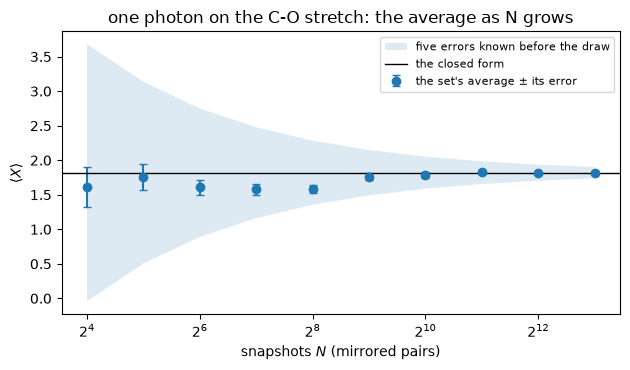

In [11]:
motion = v.motion(warm, modes=stiff).with_mode(k_s, warm.add_quantum())
print("set apart:", motion.set_apart_modes)
var_ph = pair_var(mean_ph, mean2_ph)
Ns = [2 ** j for j in range(4, 14)]
rows = []
for N in Ns:
    s = motion.sample(N, seed=SEED, antithetic=True)
    col = list(s.mode_index_1based).index(k_s)
    assert np.array_equal(s.q_amu12_ang[1::2, col], photon.draw(N // 2, seed=SEED))
    est = s.standard_error(X(s))
    known = math.sqrt(var_ph / (N / 2))                 # the pair means' error, before the draw
    assert abs(est.value - mean_ph) <= 5 * known, (N, est.value, mean_ph, known)
    rows.append((N, est.value, est.error, known))
    print(f"N {N:>5}: {est.value:.5f} ± {est.error:.5f}  (known before the draw: ± {known:.5f})")
# THE ERROR THE SET STATES is its pair means' spread: at the largest set, their
# variance against the closed form within five of its own standard errors.
x = X(s)[1:]
pm = (x[0::2] + x[1::2]) / 2
dev = (pm - pm.mean()) ** 2
assert abs(est.error ** 2 * len(pm) - var_ph) < 5 * dev.std() / math.sqrt(len(pm))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
n_, val, err, kn = map(np.array, zip(*rows))
ax.errorbar(n_, val, yerr=err, fmt="o", capsize=3, label="the set's average ± its error")
ax.fill_between(n_, mean_ph - 5 * kn, mean_ph + 5 * kn, alpha=0.15, label="five errors known before the draw")
ax.axhline(mean_ph, color="k", lw=1, label="the closed form")
ax.set_xscale("log", base=2)
ax.set_xlabel("snapshots $N$ (mirrored pairs)")
ax.set_ylabel(r"$\langle X\rangle$")
ax.set_title("one photon on the C-O stretch: the average as N grows")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. An antithetic pair's cancellation, and `parts`

With `antithetic=True` each snapshot is followed by its mirror, every $Q_k \to -Q_k$: a response odd in $Q$ cancels in every pair exactly, and `snaps.parts(values)` splits the set's spread into the pair means' (the even part's) and the half-differences' (the odd part's) — science § 5.5, whether pairs help. On $X$ itself, $X(Q)X(-Q) = 1$ for every pair, and the two parts' variances are $\tfrac12(\langle X^2\rangle + 1) - \langle X\rangle^2$ and $\tfrac12(\langle X^2\rangle - 1)$, each held within five of its own standard errors.

X's even part, its variance: 0.28065 against 0.31601
X's odd part, its variance: 1.06977 against 1.11100
a . Q: even part 0.0, odd part 0.7649;  (a . Q)^2: even 0.8033, odd 0.0


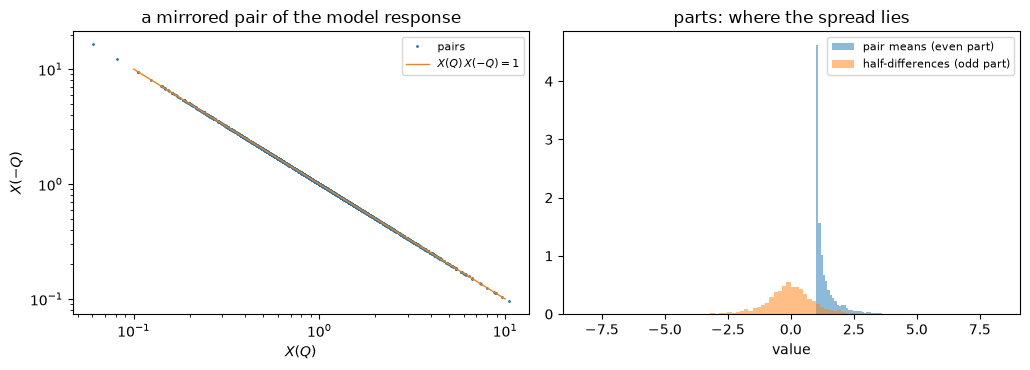

In [12]:
s5 = v.motion(warm, modes=stiff).sample(8192, seed=SEED, antithetic=True)
q = s5.q_amu12_ang
assert np.array_equal(q[1::2], -q[2::2])                  # each snapshot, then its mirror
odd = linear(q, s5.mode_index_1based)                     # a . Q
even = odd ** 2                                           # (a . Q)^2
assert s5.standard_error(odd).value == 0.0                # an odd response averages to zero, exactly
po, pe = s5.parts(odd), s5.parts(even)
assert po.even == 0.0 and po.odd > 0.0
assert pe.odd == 0.0 and pe.even > 0.0
x5 = np.exp(odd)
assert np.allclose(x5[1::2] * x5[2::2], 1.0, rtol=1e-12, atol=0)
px = s5.parts(x5)
pm, half = (x5[1::2] + x5[2::2]) / 2, (x5[1::2] - x5[2::2]) / 2
for got, closed, y, name in ((px.even ** 2, pair_var(mean_th, mean2_th), pm, "even"),
                             (px.odd ** 2, (mean2_th - 1) / 2, half, "odd")):
    dev = (y - y.mean()) ** 2
    assert abs(got - closed) < 5 * dev.std() / math.sqrt(len(y)), name
    print(f"X's {name} part, its variance: {got:.5f} against {closed:.5f}")
print(f"a . Q: even part {po.even}, odd part {po.odd:.4f};  (a . Q)^2: even {pe.even:.4f}, odd {pe.odd}")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.4, 3.8))
ax.loglog(x5[1::2][:2000], x5[2::2][:2000], ".", ms=2, label="pairs")
t = np.logspace(-1, 1, 50)
ax.loglog(t, 1 / t, lw=1, label=r"$X(Q)\,X(-Q) = 1$")
ax.set_xlabel(r"$X(Q)$")
ax.set_ylabel(r"$X(-Q)$")
ax.set_title("a mirrored pair of the model response")
ax.legend(fontsize=8)
bx.hist(pm, bins=80, alpha=0.5, density=True, label="pair means (even part)")
bx.hist(half, bins=80, alpha=0.5, density=True, label="half-differences (odd part)")
bx.set_xlabel("value")
bx.set_title("parts: where the spread lies")
bx.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. A set against its variation in one mode — one seed

Each mode draws from its own stream, keyed by its number, so the thermal set and its variation — the same seed, the C–O stretch set apart with one photon — differ by the stretch's draws alone: every other mode's column is the same, bit for bit (`engines/vibration-frames.md` § 3.3). The difference of the two sets' averages, taken frame by frame (`varied.standard_error(X(varied) - X(base))`), against the difference of the two closed forms within five of its error — and that error against the one two independent seeds give, which science § 5.5 says is larger.

the photon's effect, closed form: +0.47995
  one seed:  +0.48547 ± 0.01644
  two seeds: +0.52109 ± 0.04203


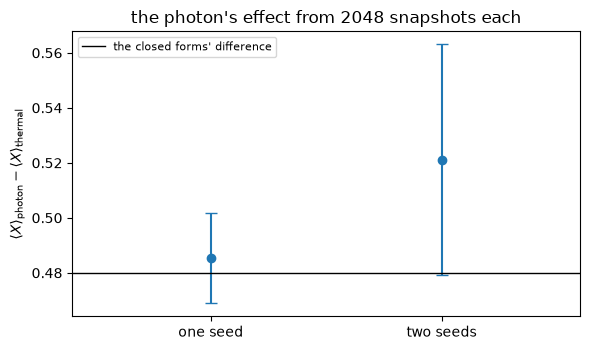

In [13]:
N6 = 2048
base = v.motion(warm, modes=stiff).sample(N6, seed=SEED, antithetic=True)
varied = v.motion(warm, modes=stiff).with_mode(k_s, warm.add_quantum()).sample(N6, seed=SEED, antithetic=True)
assert np.array_equal(base.mode_index_1based, varied.mode_index_1based)
other = base.mode_index_1based != k_s
assert np.array_equal(base.q_amu12_ang[:, other], varied.q_amu12_ang[:, other])
one_seed = varied.standard_error(X(varied) - X(base))
closed = mean_ph - mean_th
assert abs(one_seed.value - closed) <= 5 * one_seed.error
apart = v.motion(warm, modes=stiff).with_mode(k_s, warm.add_quantum()).sample(N6, seed=SEED + 1, antithetic=True)
a_, b_ = apart.standard_error(X(apart)), base.standard_error(X(base))
two_seeds = (a_.value - b_.value, math.hypot(a_.error, b_.error))
assert one_seed.error < two_seeds[1]
print(f"the photon's effect, closed form: {closed:+.5f}")
print(f"  one seed:  {one_seed.value:+.5f} ± {one_seed.error:.5f}")
print(f"  two seeds: {two_seeds[0]:+.5f} ± {two_seeds[1]:.5f}")

fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.errorbar([0, 1], [one_seed.value, two_seeds[0]], yerr=[one_seed.error, two_seeds[1]], fmt="o",
            capsize=4)
ax.axhline(closed, color="k", lw=1, label="the closed forms' difference")
ax.set_xticks([0, 1], ["one seed", "two seeds"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel(r"$\langle X\rangle_{\mathrm{photon}} - \langle X\rangle_{\mathrm{thermal}}$")
ax.set_title(f"the photon's effect from {N6} snapshots each")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. More frames later — two sets, their results put end to end

The streams are drawn in blocks, so the same seed drawn further, `sample(N, seed=, start=N)`, is the next $N$ snapshots — `sample(2N)` begins with `sample(N)`. Each part is written as a set of its own (`write_frame_set`, into the temporary tree's `structure/` topic) and read back; the two calculations' results are then put end to end as `engines/vibration-frames.md` § 7's worked lines do: each set's values and stored weights, frame 0 left out, each set's weights scaled by its share of the whole, the average and its error from the pair means (`sampling.pair_means`, `sampling.mean_with_error`) — the one set of $2N$'s, within science § 2e.6's one epsilon.

written: P/structure/methanol-photon-a.xyz and methanol-photon-b.xyz -- 513 frames each
methanol's deck records no settings (a PySCF deck states none), so the set states no info.calculation and is no transport citation


the two sets end to end: 1.792189 ± 0.042146;  one set of 1024: 1.792189 ± 0.042146


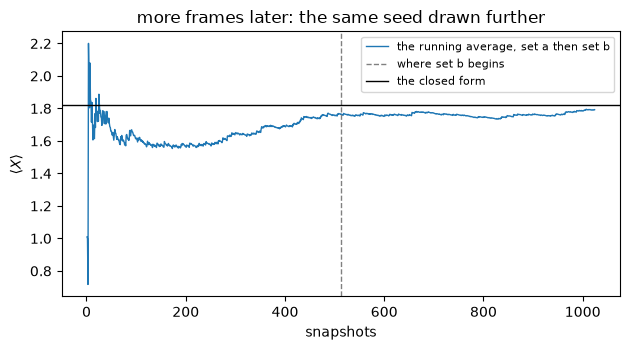

In [14]:
N7 = 512
s1 = motion.sample(N7, seed=SEED, antithetic=True)
s2 = motion.sample(N7, seed=SEED, antithetic=True, start=N7)
whole = motion.sample(2 * N7, seed=SEED, antithetic=True)
assert np.array_equal(whole.q_amu12_ang[1:], np.vstack([s1.q_amu12_ang[1:], s2.q_amu12_ang[1:]]))
w1 = write_frame_set(topic_dir("P", "structure") / "methanol-photon-a.xyz", s1)
w2 = write_frame_set(topic_dir("P", "structure") / "methanol-photon-b.xyz", s2)
assert w1.n_frames == w2.n_frames == N7 + 1
print("written:", w1.path.relative_to(tree), "and", w2.path.name, f"-- {w1.n_frames} frames each")
print(*w1.said, sep="\n")
r1, r2 = read_frame_set(w1.path), read_frame_set(w2.path)
both = np.concatenate([X(r1)[1:], X(r2)[1:]])
weights = np.concatenate([r1.weights[1:], r2.weights[1:]]) / 2       # each set half the whole
value, error = sampling.mean_with_error(*sampling.pair_means(both, weights))
single = whole.standard_error(X(whole))
assert math.isclose(value, single.value, rel_tol=1e-12)
assert math.isclose(error, single.error, rel_tol=1e-12)
print(f"the two sets end to end: {value:.6f} ± {error:.6f};  one set of {2 * N7}: {single.value:.6f} ± {single.error:.6f}")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
running = np.cumsum(both) / np.arange(1, len(both) + 1)
ax.plot(np.arange(1, len(both) + 1), running, lw=1, label="the running average, set a then set b")
ax.axvline(N7, color="0.5", ls="--", lw=1, label="where set b begins")
ax.axhline(mean_ph, color="k", lw=1, label="the closed form")
ax.set_xlabel("snapshots")
ax.set_ylabel(r"$\langle X\rangle$")
ax.set_title("more frames later: the same seed drawn further")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 12. A set written and read back

`read_frame_set(path)` with no vibration given reopens the run its `vibration_run` row names — here, in the temporary tree — and binds the motion it recorded again. It is the set as written: item $i$ is frame $i$, frame 0 the relaxed geometry at weight 0; its weights as its file states them; its frames' geometries as written (`written_positions_ang`, the same within the pair's $10^{-6}$ Å — the plot draws them, the file's own); and its rows as written (`rows`, the structure's own reader's). A calculation's results pair with its frames by the file, so its analyses take one value per frame, frame 0 first.

Snapshots(512 snapshots of 11 modes, mirrored pairs, seed 20261127, start 0)
  the largest single-atom move is 0.5323 Å, frame 344 of 513, mode 4 moving it most; each mode's spread (amu^1/2·Å): mode 2 0.126, mode 3 0.214, mode 4 0.12, mode 5 0.111, mode 6 0.107, mode 7 0.107, mode 8 0.106, mode 9 0.0754, mode 10 0.0748, mode 11 0.0737, mode 12 0.0664
its rows: vibration_run, vibration_result_sha256, mass_source, assumptions, sampling_rule, samples, seed, start, rng, antithetic, modes, set_apart_modes, quantum, temperature_k


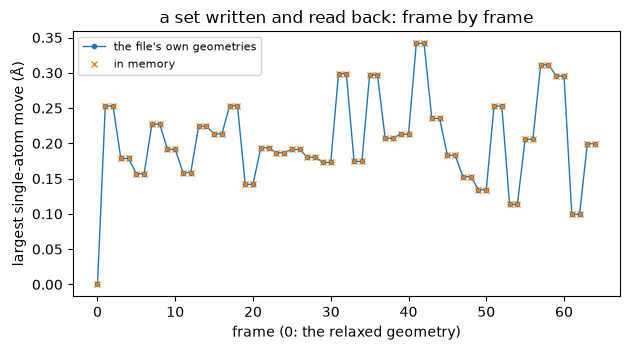

In [15]:
r = read_frame_set(w1.path)
assert type(r).__name__ == "Snapshots" and r.motion is not None
assert list(r.mode_index_1based) == moving                  # the modes section 2 chose, as written
assert np.array_equal(r.q_amu12_ang, s1.q_amu12_ang)
assert r.weights[0] == 0.0 and np.array_equal(r.weights[1:], np.full(N7, 1 / N7))
assert np.array_equal(r.weights, np.array(r.rows.weights))
assert (r.rows.value("samples"), r.rows.value("seed"), r.rows.value("antithetic")) == (N7, SEED, 1)
assert np.array_equal(X(r), X(s1))
assert r.standard_error(X(r)).value == s1.standard_error(X(s1)).value
assert np.abs(r.written_positions_ang - s1.positions_ang).max() <= 1e-6
print(r)
print("its rows:", ", ".join(row["name"] for row in r.rows.structure))

on_file = np.linalg.norm(r.written_positions_ang - r.written_positions_ang[:1], axis=2).max(axis=1)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
frames = np.arange(len(r.weights))
ax.plot(frames[:65], on_file[:65], "o-", ms=3, lw=1, label="the file's own geometries")
ax.plot(frames[:65], s1.max_atom_displacement_ang[:65], "x", ms=4, label="in memory")
ax.set_xlabel("frame (0: the relaxed geometry)")
ax.set_ylabel("largest single-atom move (Å)")
ax.set_title("a set written and read back: frame by frame")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 13. A mode's own set — two states, each by its own rule, against one re-weighted

For one mode alone a few deterministic frames do far better than snapshots: `mode.bind(chain).frames(nodes)`, the Gauss rule of the state's own distribution, $m$ = `nodes` frames exact for a response polynomial to degree $2m - 1$ (`engines/vibration-frames.md` § 4). The C–O stretch's thermal set and its photon set, five frames each, are written and read back; each one's average of the stretch's own factor, $e^{a Q}$, is held to its closed form within the rule's remainder past degree 9 — the averages of $Q^k$ it reproduces, $k \le 9$, held to the science's ($\sigma^k (k-1)!!$ thermal; for the photon, science § 2d.4's mix, $Q_{\mathrm{zp}}^k s^{k/2}(k-1)!!\,(\bar n + (\bar n + 1)(k + 1))/s$, $s = 2\bar n + 1$) within science § 2e.6's one epsilon. Re-weighting the thermal set's frames to the photon — `weights_at(q, written=…)`, and `weights_for_set` on the set's rows read back, the same — is said: the share of the photon's motion beyond the frames, exact to degree $m$ at least, and it averages the photon worse than the photon's own set. Frames placed for a state, weighted for it, are its own rule.

   thermal, its own five frames: 1.1972171 against 1.1972174
one photon, its own five frames: 1.6261016 against 1.6261032
the thermal set re-weighted to the photon: 1.6260469, exact to degree 7
4.26 % of the state's motion lies beyond the outermost frames (q from -0.3542 to +0.3542 amu^1/2·Å), averaged by values the frames never computed


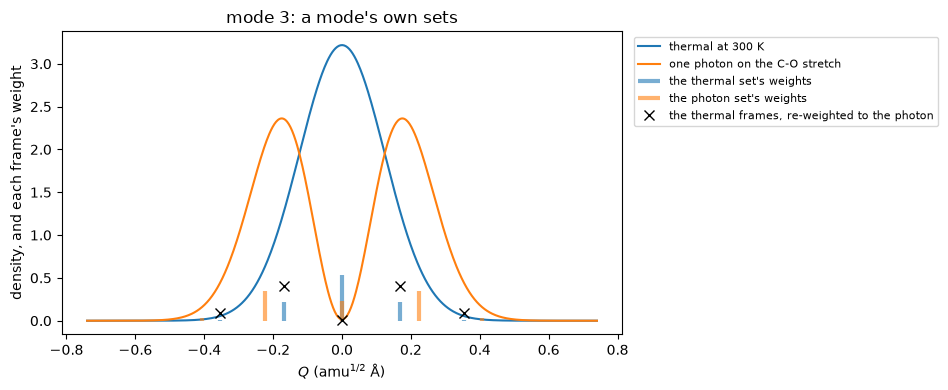

In [16]:
d_th, d_ph = stretch.bind(warm), stretch.bind(warm.add_quantum())
# THE SCIENCE'S MOMENTS, ON THE MODE'S OWN NUMBERS (its spread, Q_zp and mean
# quanta, CODATA's within 1e-8, section 2): (k - 1)!! is 1 for k = 0.


def double_factorial(k):
    return math.prod(range(k, 0, -2))


def moment_th(k):
    return 0.0 if k % 2 else sigma_s ** k * double_factorial(k - 1)


def moment_ph(k):
    s = 2 * nbar_s + 1
    return 0.0 if k % 2 else (qz ** k * s ** (k / 2) * double_factorial(k - 1)
                              * (nbar_s + (nbar_s + 1) * (k + 1)) / s)


wth = write_frame_set(topic_dir("P", "structure") / "methanol-stretch-thermal.xyz", d_th.frames(5))
wph = write_frame_set(topic_dir("P", "structure") / "methanol-stretch-photon.xyz", d_ph.frames(5))
rth, rph = read_frame_set(wth.path), read_frame_set(wph.path)
assert type(rth).__name__ == type(rph).__name__ == "Frames"
at = a[k_s]
for rs, moment, closed, name in ((rth, moment_th, thermal_mgf(k_s), "thermal"),
                                 (rph, moment_ph, list_mgf(photon_list, k_s), "one photon")):
    qs, ws = rs.q_amu12_ang[:, 0], rs.weights
    assert rs.exact_to_degree == 9
    for k in range(10):
        terms = ws * qs ** k
        # science § 2e.6's one epsilon, 1e-12 of the size of what is compared
        assert abs(terms.sum() - moment(k)) <= 1e-12 * max(np.abs(terms).sum(), abs(moment(k)))
    remainder = sum(abs(at) ** k * (np.sum(np.abs(ws) * np.abs(qs) ** k) + abs(moment(k)))
                    / math.factorial(k) for k in range(10, 80))
    got = float(ws @ np.exp(at * qs))
    assert abs(got - closed) <= remainder
    print(f"{name:>10}, its own five frames: {got:.7f} against {closed:.7f}")

qt, qp = rth.q_amu12_ang[:, 0], rph.q_amu12_ang[:, 0]
pw = d_ph.weights_at(qt, written=rth.weights)
assert not pw.own and pw.exact_to_degree >= 5
assert any("beyond the outermost frames" in said for said in pw.said)
from_rows = weights_for_set(rth.rows, warm.add_quantum())
assert np.array_equal(from_rows.weights, pw.weights) and from_rows.said == pw.said
re_weighted = float(pw.weights @ np.exp(at * qt))
own_set = float(rph.weights @ np.exp(at * qp))
closed_ph = list_mgf(photon_list, k_s)
assert abs(re_weighted - closed_ph) > abs(own_set - closed_ph)
own = d_ph.weights_at(qp, written=rph.weights)
assert own.own and own.exact_to_degree == 9 and own.said == ()
assert np.allclose(own.weights, rph.weights, rtol=0, atol=1e-12)
print(f"the thermal set re-weighted to the photon: {re_weighted:.7f}, exact to degree {pw.exact_to_degree}")
print(*pw.said, sep="\n")

xs = np.linspace(-6 * qz, 6 * qz, 600)
fig, ax = plt.subplots(figsize=(9.6, 4.0))
ax.plot(xs, d_th.distribution.pdf(xs), label="thermal at 300 K")
ax.plot(xs, d_ph.distribution.pdf(xs), label="one photon on the C-O stretch")
ax.vlines(qt, 0, rth.weights, colors="C0", lw=3, alpha=0.6, label="the thermal set's weights")
ax.vlines(qp, 0, rph.weights, colors="C1", lw=3, alpha=0.6, label="the photon set's weights")
ax.plot(qt, pw.weights, "kx", ms=7, label="the thermal frames, re-weighted to the photon")
ax.set_xlabel(r"$Q$ (amu$^{1/2}$ Å)")
ax.set_ylabel("density, and each frame's weight")
ax.set_title(f"mode {k_s}: a mode's own sets")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

## What was checked

Each `assert` above holds the toolkit to the science on a real vibration: the run's provenance; each mode's zero-point amplitude, thermal quanta and spread against CODATA; the stiff mode found from the run, its photon under science § 7's 1 eV mark (a mark, not a bound) and its moves printed beside the bond; the snapshots' modes chosen from the run, the soft torsion left out; draws from the state's distribution, number by number; the Gauss rules of two kinds of quanta; the events' lists; every atom's displacement covariance; the molecule's average with one photon on the C–O stretch against its closed form at every $N$, the stretch's column the photon's own draws, with its error known before the draw; the mirrored pairs' exact cancellation and their even and odd parts; a variation in one mode on one seed; two sets put end to end; a set read back as written, its rows among it; and a mode's own sets against their closed forms, re-weighted and not. Change a state, a seed, a coefficient or the run, and *Run All* again — every check takes its expectation from the science, not from what it printed last time.